# Kesit İstatistik — Çok değişkenli olasılık modelleri

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Çok değişkenli normal ve Mahalanobis uzaklığı

Korelasyonlu iki ölçümde uzaklığı nasıl değerlendiririm?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı Öklid uzaklığında noktaların Mahalanobis farkını gör.

**Yorum sınırı:** Kovaryans tahmini bağımsız referanstan gelir; yüksek boyut/az örneklemde regularizasyon gerekir.

**Alıştırma:** Korelasyonu .85’ten 0’a indir; eliptik uzaklığın değişimini incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'noktalar': [[2, 2], [2, -2]], 'Mahalanobis_kare': [5.036603068444901, 54.20687505846167], 'chi2_95': np.float64(5.991464547107979)}


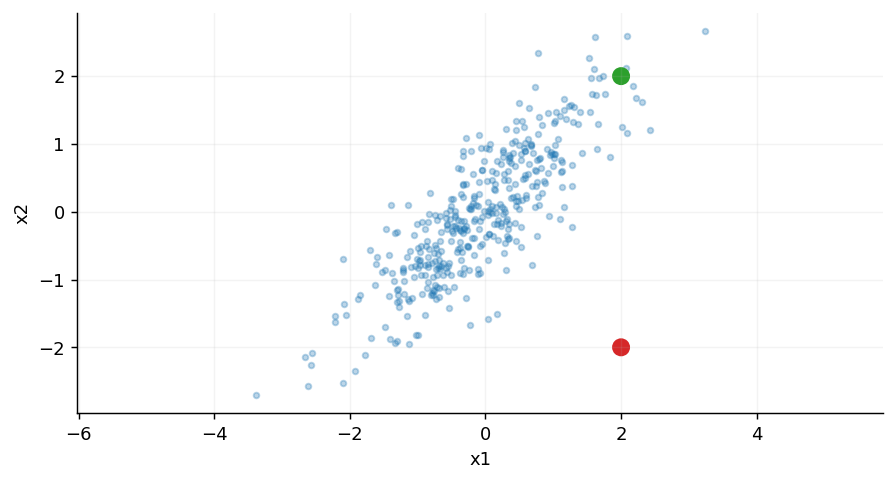

In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

X=rng.multivariate_normal([0,0],[[1,.85],[.85,1]],400);cov=np.cov(X,rowvar=False);center=X.mean(axis=0);points=np.array([[2,2],[2,-2]]);delta=points-center;dist2=np.einsum('ij,jk,ik->i',delta,np.linalg.inv(cov),delta);print({'noktalar':points.tolist(),'Mahalanobis_kare':dist2.tolist(),'chi2_95':stats.chi2.ppf(.95,2)})
plt.scatter(*X.T,s=10,alpha=.3);plt.scatter(*points.T,s=80,c=['tab:green','tab:red']);plt.axis('equal');plt.xlabel('x1');plt.ylabel('x2')

## Gaussian karışımlar ve EM

EM ile yumuşak küme üyeliğini nasıl öğrenirim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Sert etiket yerine üyelik olasılığı ve BIC’yi birlikte incele.

**Yorum sınırı:** Karışım etiketleri yer değiştirebilir; yerel optimum ve normal bileşen varsayımı kontrol edilir.

**Alıştırma:** Bileşen ortalamalarını yaklaştır; üyelik belirsizliğini gör.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


   bilesen          BIC  yakinsadi
0        1  1587.072667       True
1        2  1491.515717       True
2        3  1509.129477       True
3        4  1523.128281       True
Ortalama: [-1.4289  1.6145] Ağırlık: [0.4646 0.5354]


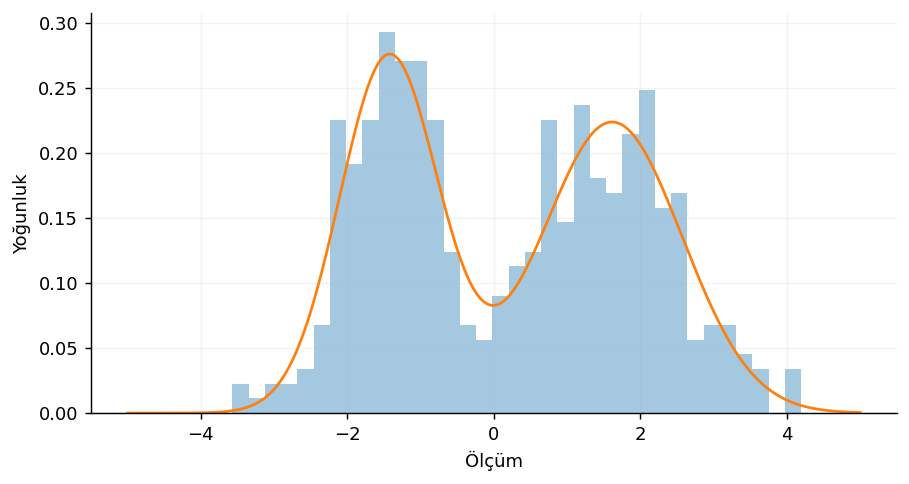

In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.mixture import GaussianMixture
X=np.r_[rng.normal(-1.5,.7,(180,1)),rng.normal(1.5,1,(220,1))];rows=[];models=[]
for k in [1,2,3,4]:
 m=GaussianMixture(k,n_init=5,random_state=7).fit(X);models.append(m);rows.append([k,m.bic(X),m.converged_])
print(pd.DataFrame(rows,columns=['bilesen','BIC','yakinsadi']));m=models[1];print('Ortalama:',m.means_.ravel(),'Ağırlık:',m.weights_);grid=np.linspace(-5,5,300)[:,None];plt.hist(X.ravel(),bins=35,density=True,alpha=.4);plt.plot(grid[:,0],np.exp(m.score_samples(grid)));plt.xlabel('Ölçüm');plt.ylabel('Yoğunluk')

## Faktör analizi ve gizli değişkenler

Ortak faktör ile toplam varyans aynı hedef mi?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Faktör yükleri ve özgül hata varyanslarını ayır.

**Yorum sınırı:** Faktörün işareti/rotasyonu tanımlanabilirlik sınırı taşır; faktörler kendiliğinden gerçek neden değildir.

**Alıştırma:** Son ölçümün hata sapmasını artır; özgül varyansı incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'yukler': [[-0.9682870992856426, -0.7540028695641754, -0.5376334983836656, -1.1359040492971137]], 'ozgul_varyans': [0.08752570486027322, 0.2592326809545812, 0.9984328635419379, 0.16849395623375774]}


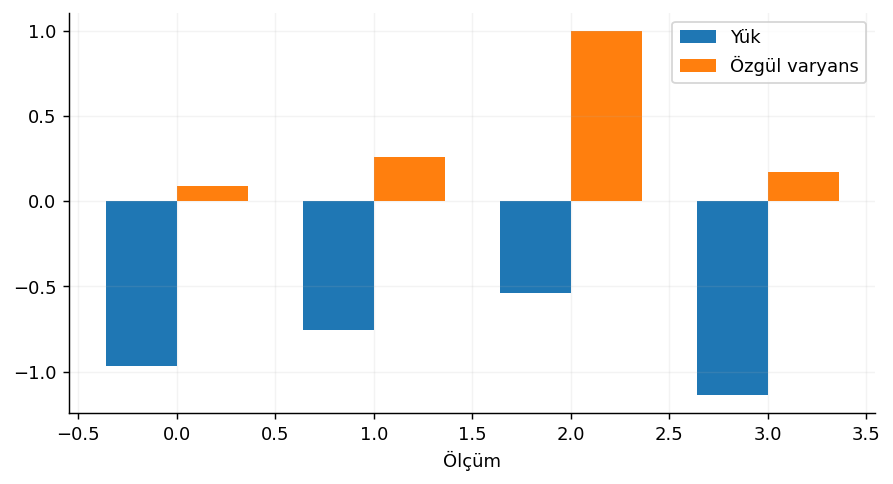

In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.decomposition import FactorAnalysis
latent=rng.normal(size=(400,1));load=np.array([[1,.8,.6,1.2]]);X=latent@load+rng.normal(size=(400,4))*np.array([.3,.5,1.,.4]);m=FactorAnalysis(1,random_state=7).fit(X);print({'yukler':m.components_.tolist(),'ozgul_varyans':m.noise_variance_.tolist()});plt.bar(np.arange(4)-.18,m.components_[0],.36,label='Yük');plt.bar(np.arange(4)+.18,m.noise_variance_,.36,label='Özgül varyans');plt.xlabel('Ölçüm');plt.legend()

## Manifold, t-SNE/UMAP ve görsel yanılsamalar

İki boyutlu adalar doğal sınıf kanıtı mı?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı noktaların farklı perplexity değerlerinde yerleşimini karşılaştır.

**Yorum sınırı:** t-SNE eksenleri ve küme arası uzaklık global geometri değildir; UMAP burada eğitilmez, ayrı algoritmadır.

**Alıştırma:** Perplexity=10 yerine 50 kullan; etiketlerin değişmediğini, yerleşimin değiştiğini göster.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'KL_objektif': 0.5509330630302429, 'n': 180, 'perplexity': 20}


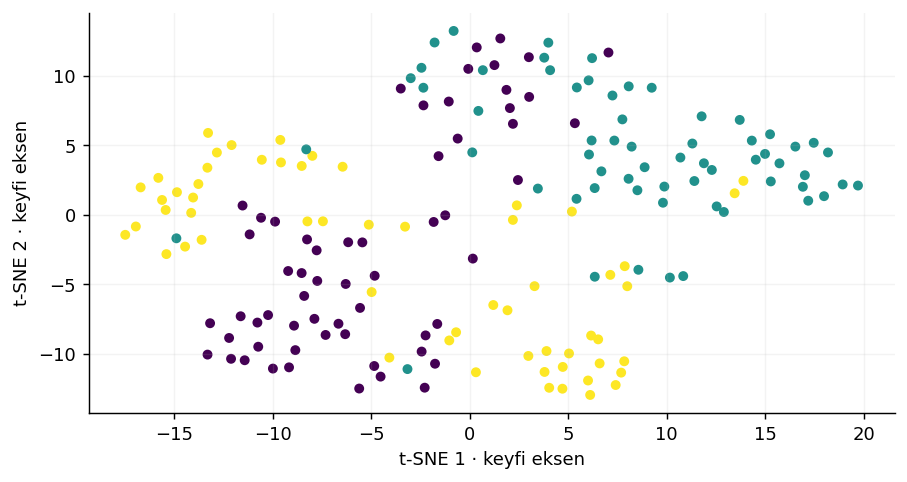

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.manifold import TSNE
X,y=make_classification(n_samples=180,n_features=6,n_informative=3,n_classes=3,n_clusters_per_class=1,random_state=7);X=StandardScaler().fit_transform(X);m=TSNE(perplexity=20,max_iter=500,init='pca',random_state=7);z=m.fit_transform(X);print({'KL_objektif':m.kl_divergence_,'n':len(X),'perplexity':20});plt.scatter(*z.T,c=y,s=20,cmap='viridis');plt.xlabel('t-SNE 1 · keyfi eksen');plt.ylabel('t-SNE 2 · keyfi eksen')